# Diagnóstico de Residuos
**Proyecto Integrador · Aprendizaje Profundo**
Estación A001 — Brasília, DF · 2020–2026

---

## 1. Introducción

Un modelo de pronóstico de series temporales es adecuado no solo si tiene métricas de error bajas, sino también si sus residuos son **ruido blanco**: independientes, con media cero y sin estructura temporal. Este cuaderno diagnostica los residuos del MLP con:

1. **Prueba BDS** (*Brock, Dechert & Scheinkman*, 1996): prueba de independencia serial no lineal que detecta dependencia más allá de la correlación lineal.
2. **ACF de residuos** y **ACF de residuos al cuadrado** (heterocedasticidad residual).
3. **Distribución de residuos** (histograma y QQ-plot).
4. **Residuos en el tiempo**, para detectar patrones temporales.

El diagnóstico usa los residuos del horizonte $h = 1$ que guardó el cuaderno 3: los de **validación** de cada fold, para las tres estrategias, y los del **hold-out** para el modelo final de cada horizonte. Son residuos fuera de muestra, porque cada modelo predice ventanas que no vio al entrenar.

---

## 2. Importar librerías

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import bds

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.prop_cycle': matplotlib.cycler('color', ['#000000', '#444444', '#888888', '#bbbbbb']),
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.size': 10, 'axes.titlesize': 11,
})

BASE_DIR    = os.path.dirname(os.getcwd())
RESULTS_DIR = os.path.join(BASE_DIR, 'results')
FIGS_DIR    = os.path.join(os.getcwd(), 'figs')
os.makedirs(FIGS_DIR, exist_ok=True)
print('Librerías cargadas.')

Librerías cargadas.


## 3. Cargar residuos de validación y de hold-out

El residuo del primer paso se define como $\text{resid}_t = y_t^{\text{real}} - \hat{y}_t$. El análisis detallado se hace sobre el horizonte H = 7 con el lag elegido para su modelo final.

In [2]:
preds = pd.read_csv(os.path.join(RESULTS_DIR, 'predicciones_h1.csv'), parse_dates=['fecha'])
ho_pred = pd.read_csv(os.path.join(RESULTS_DIR, 'holdout_predicciones.csv'), parse_dates=['fecha'])
ho_eval = pd.read_csv(os.path.join(RESULTS_DIR, 'holdout_evaluation.csv'))

val = preds[preds.conjunto == 'val'].copy()
val['resid'] = val['real'] - val['pred']
ho_pred['resid'] = ho_pred['real'] - ho_pred['pred']

H_SHOW = 7
LAG_SHOW = int(ho_eval.loc[ho_eval.horizonte == H_SHOW, 'lag'].iloc[0])
print(f'Residuos de validación: {len(val)} ({val.estrategia.nunique()} estrategias × 16 combinaciones × 5 folds)')
print(f'Residuos de hold-out  : {len(ho_pred)} (modelos finales H = 7, 14, 21, 28)')
print(f'Combinación analizada en detalle: lag={LAG_SHOW}, H={H_SHOW}')

Residuos de validación: 12664 (3 estrategias × 16 combinaciones × 5 folds)
Residuos de hold-out  : 930 (modelos finales H = 7, 14, 21, 28)
Combinación analizada en detalle: lag=21, H=7


## 4. Prueba BDS de independencia serial en validación

La prueba BDS evalúa la hipótesis nula $H_0$ de que los residuos son independientes e idénticamente distribuidos (iid). Bajo $H_0$ el estadístico sigue asintóticamente una normal estándar. Un p-valor $> 0{,}05$ indica que **no se rechaza** $H_0$, señal de que el modelo capturó la dependencia de la serie. Se aplica a los residuos de $h = 1$ de cada fold y de cada estrategia (dimensión de inmersión 2, `statsmodels`).

En validación, las ventanas consecutivas de un fold están separadas por 7 días (`numJumps = 7`). La prueba evalúa entonces la dependencia entre residuos semanales, no diarios.

In [3]:
def bds_test(resid):
    try:
        stat, pval = bds(np.asarray(resid, dtype=float), max_dim=2)
        return float(np.atleast_1d(stat)[0]), float(np.atleast_1d(pval)[0])
    except Exception:
        return float('nan'), float('nan')


filas = []
for (estrategia, lag, H, fold), g in val.sort_values('fecha').groupby(['estrategia', 'lag', 'horizonte', 'fold']):
    stat, pval = bds_test(g['resid'].values)
    filas.append({'estrategia': estrategia, 'lag': lag, 'horizonte': H, 'fold': fold, 'n_obs': len(g),
                  'BDS_stat': stat, 'BDS_pvalue': pval,
                  'rmse_val': float(np.sqrt(np.mean(g['resid'] ** 2)))})
bds_val = pd.DataFrame(filas)
bds_val['conclusion'] = np.where(bds_val.BDS_pvalue > 0.05, 'iid (no rechazo H0)', 'NO iid (rechazo H0)')
bds_val.to_csv(os.path.join(RESULTS_DIR, 'bds_validacion.csv'), index=False)

print(f'=== Prueba BDS en validación (h=1) — lag={LAG_SHOW}, H={H_SHOW} ===')
display(bds_val[(bds_val.lag == LAG_SHOW) & (bds_val.horizonte == H_SHOW)].round(4).reset_index(drop=True))

print('=== Validación: proporción de folds con residuos iid (p > 0,05), por estrategia y horizonte ===')
display(bds_val.assign(iid=bds_val.BDS_pvalue > 0.05)
        .pivot_table(index='estrategia', columns='horizonte', values='iid', aggfunc='mean').round(3))

=== Prueba BDS en validación (h=1) — lag=21, H=7 ===


,estrategia,lag,horizonte,fold,n_obs,BDS_stat,BDS_pvalue,rmse_val,conclusion
0,forwardChaining,21,7,1,52,0.3604,0.7185,0.4946,iid (no rechazo H0)
1,forwardChaining,21,7,2,53,0.0982,0.9218,0.4828,iid (no rechazo H0)
2,forwardChaining,21,7,3,52,0.0496,0.9605,0.4869,iid (no rechazo H0)
3,forwardChaining,21,7,4,52,-0.1958,0.8447,0.4737,iid (no rechazo H0)
4,forwardChaining,21,7,5,53,-0.1560,0.8760,0.4610,iid (no rechazo H0)
5,groupKFold,21,7,1,35,-0.4081,0.6832,0.5018,iid (no rechazo H0)
6,groupKFold,21,7,2,35,1.6193,0.1054,0.5430,iid (no rechazo H0)
7,groupKFold,21,7,3,35,-0.0906,0.9278,0.4581,iid (no rechazo H0)
8,groupKFold,21,7,4,35,-1.2060,0.2278,0.5701,iid (no rechazo H0)
9,groupKFold,21,7,5,36,0.3072,0.7587,0.5770,iid (no rechazo H0)


=== Validación: proporción de folds con residuos iid (p > 0,05), por estrategia y horizonte ===


horizonte,7,14,21,28
estrategia,,,,
forwardChaining,1.0,1.00,0.85,0.95
groupKFold,0.9,0.80,0.85,0.85
kFold,0.9,0.95,0.90,0.85


**Interpretación.** Para lag = 21 y H = 7, la combinación del modelo final, ninguno de los 15 folds rechaza la independencia: los p-valores van de 0,72 a 0,96 en Forward Chaining, de 0,60 a 0,86 en K-Fold y de 0,11 a 0,93 en Group K-Fold. En las 16 combinaciones, la proporción de folds con residuos compatibles con iid es del 95 % en Forward Chaining (100 % con H = 7 y H = 14), del 90 % en K-Fold y del 85 % en Group K-Fold.

Esto significa que, a escala semanal, el MLP no deja dependencia serial detectable en la mayoría de los folds, en especial con la estrategia que respeta el orden temporal (Brock et al., 1996). Hay que tener en cuenta dos matices: en validación los residuos de un fold corresponden a ventanas separadas por 7 días, de modo que la prueba no examina la dependencia día a día, y con 35 a 63 observaciones por fold su potencia es limitada.

Por ello, se recomienda no concluir independencia a partir de la validación y contrastar el resultado con los residuos diarios del hold-out, que son más largos (222 a 243 observaciones) y consecutivos.

## 5. Prueba BDS en el hold-out (modelos finales)

En el hold-out las ventanas avanzan de a un día, de modo que la prueba evalúa la dependencia entre residuos diarios consecutivos del modelo final.

In [4]:
filas = []
for H, g in ho_pred.sort_values('fecha').groupby('horizonte'):
    stat, pval = bds_test(g['resid'].values)
    filas.append({'horizonte': H, 'lag': int(g['lag'].iloc[0]), 'n_obs': len(g),
                  'media_resid': g['resid'].mean(), 'rmse_h1': float(np.sqrt(np.mean(g['resid'] ** 2))),
                  'BDS_stat': stat, 'BDS_pvalue': pval,
                  'conclusion': 'iid (no rechazo H0)' if pval > 0.05 else 'NO iid (rechazo H0)'})
bds_ho = pd.DataFrame(filas)
bds_ho.to_csv(os.path.join(RESULTS_DIR, 'bds_holdout.csv'), index=False)
print('=== Hold-out: prueba BDS sobre los residuos h=1 de los modelos finales ===')
display(bds_ho.round(4))

=== Hold-out: prueba BDS sobre los residuos h=1 de los modelos finales ===


,horizonte,lag,n_obs,media_resid,rmse_h1,BDS_stat,BDS_pvalue,conclusion
0,7,21,243,0.0067,0.5050,5.0224,0.0,NO iid (rechazo H0)
1,14,21,236,-0.0317,0.5300,6.4833,0.0,NO iid (rechazo H0)
2,21,21,229,-0.0325,0.5370,6.9192,0.0,NO iid (rechazo H0)
3,28,21,222,-0.0377,0.5652,9.2482,0.0,NO iid (rechazo H0)


**Interpretación.** En el hold-out la prueba BDS rechaza la independencia de los residuos del primer paso en los cuatro horizontes, con p-valores inferiores a 0,0001 sobre 222 a 243 observaciones diarias. La media de los residuos es prácticamente cero (0,007 m/s con H = 7), de modo que el modelo no tiene sesgo, pero sí deja dependencia.

Lo anterior indica que la conclusión cambia al pasar de residuos semanales a residuos diarios: el MLP no captura toda la dinámica día a día del viento, y lo que queda en los residuos son rachas de varios días por encima o por debajo de lo predicho, coherentes con un pronóstico cercano a la media (cuaderno 3, sección 10.1). La BDS no distingue si esa dependencia es lineal o no lineal; la ACF de la sección 6 ayuda a separarlas.

En consecuencia, se decide reportar que el modelo final no cumple el criterio de ruido blanco a escala diaria, y señalar como camino de mejora la incorporación de información que explique esas rachas, como la estacionalidad derivada de la fecha.

## 6. ACF de residuos y de residuos al cuadrado

Se usan los residuos diarios del hold-out del modelo final con H = 7 (fila superior) y los residuos de validación del mejor fold de Forward Chaining (fila inferior, con paso semanal).

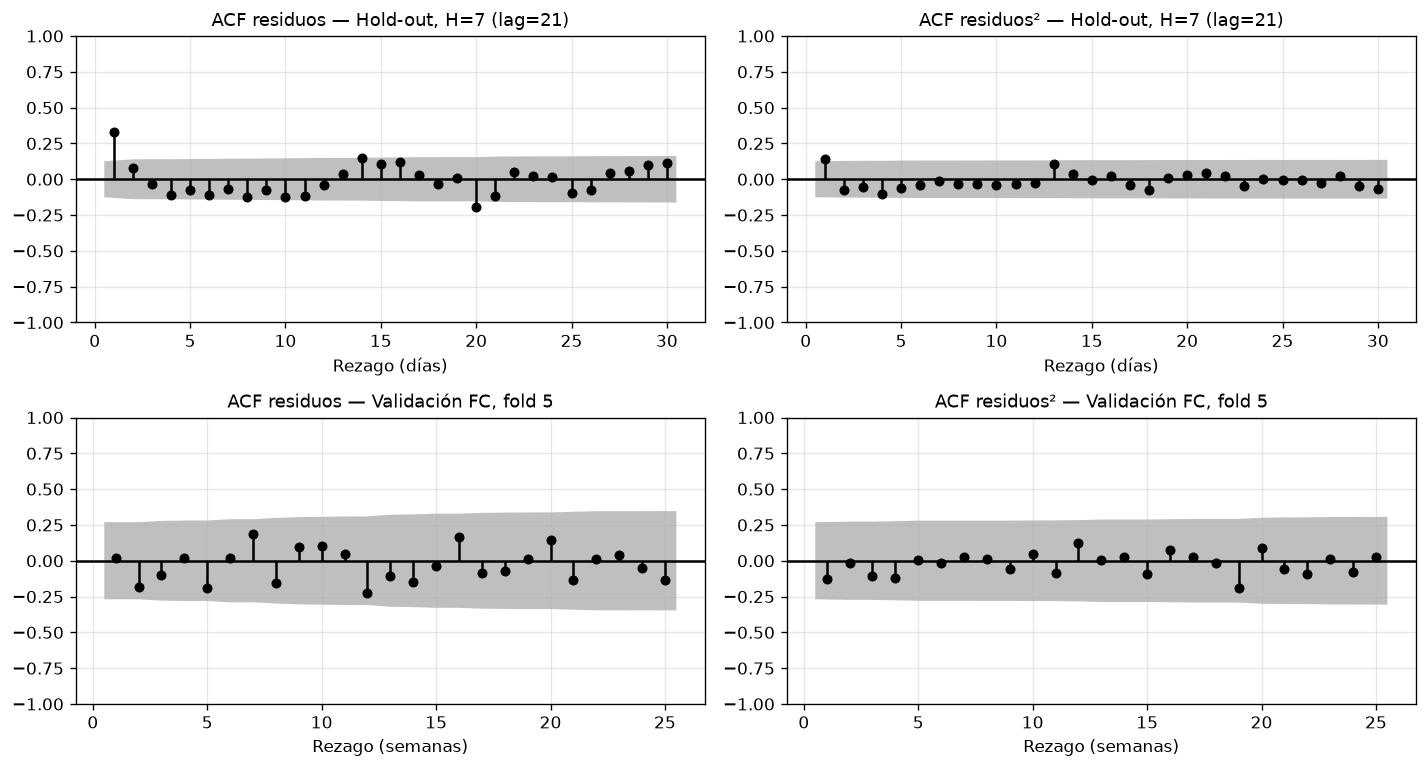

In [5]:
resid_ho = ho_pred[ho_pred.horizonte == H_SHOW].sort_values('fecha')['resid'].values
fc = bds_val[(bds_val.estrategia == 'forwardChaining') & (bds_val.lag == LAG_SHOW) & (bds_val.horizonte == H_SHOW)]
best_fold = int(fc.sort_values('rmse_val').iloc[0]['fold'])
resid_fc = val[(val.estrategia == 'forwardChaining') & (val.lag == LAG_SHOW) & (val.horizonte == H_SHOW)
               & (val.fold == best_fold)].sort_values('fecha')['resid'].values

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
series = [(resid_ho, f'Hold-out, H={H_SHOW} (lag={LAG_SHOW})', 'días'),
          (resid_fc, f'Validación FC, fold {best_fold}', 'semanas')]
for r, (res, nombre, unidad) in enumerate(series):
    nl = min(30, len(res) // 2 - 1)
    plot_acf(res, lags=nl, ax=axes[r, 0], zero=False, alpha=0.05, color='black',
             vlines_kwargs={'colors': 'black'}, title=f'ACF residuos — {nombre}')
    plot_acf(res ** 2, lags=nl, ax=axes[r, 1], zero=False, alpha=0.05, color='black',
             vlines_kwargs={'colors': 'black'}, title=f'ACF residuos² — {nombre}')
    for ax in axes[r]:
        ax.set_xlabel(f'Rezago ({unidad})')
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, f'resid_acf_h{H_SHOW}.png'), dpi=150)
plt.show()

**Interpretación.** En los residuos diarios del hold-out (H = 7) la autocorrelación del rezago 1 es de 0,334, muy por encima de la banda de confianza del 95 % ($\pm 1{,}96/\sqrt{243} \approx \pm 0{,}126$), mientras los rezagos 2 a 7 quedan dentro de la banda (entre −0,115 y 0,077). En los residuos al cuadrado el rezago 1 vale 0,139, apenas por encima de la banda. En los residuos de validación del mejor fold de Forward Chaining (fold 5), con paso semanal, el rezago 1 vale 0,017, lejos de su banda de ±0,269.

Esto quiere decir que la dependencia que detecta la BDS en el hold-out es sobre todo lineal y de muy corto plazo: el error de un día se parece al del día siguiente y esa memoria se pierde en dos o tres días, lo que explica que a escala semanal los residuos parezcan independientes. La autocorrelación débil de los residuos al cuadrado sugiere una heterocedasticidad leve, en la que los días de error grande tienden a agruparse.

De ahí que se opte por considerar, en una siguiente iteración, un modelo menos regularizado que aproveche mejor el último valor observado, o una corrección autorregresiva de orden 1 sobre los residuos, y no un modelo de varianza condicional tipo ARCH (Engle, 1982), que no se justifica con una heterocedasticidad tan débil.

## 7. Distribución de residuos (histograma y QQ-plot)

Residuos diarios del hold-out del modelo final con H = 7.

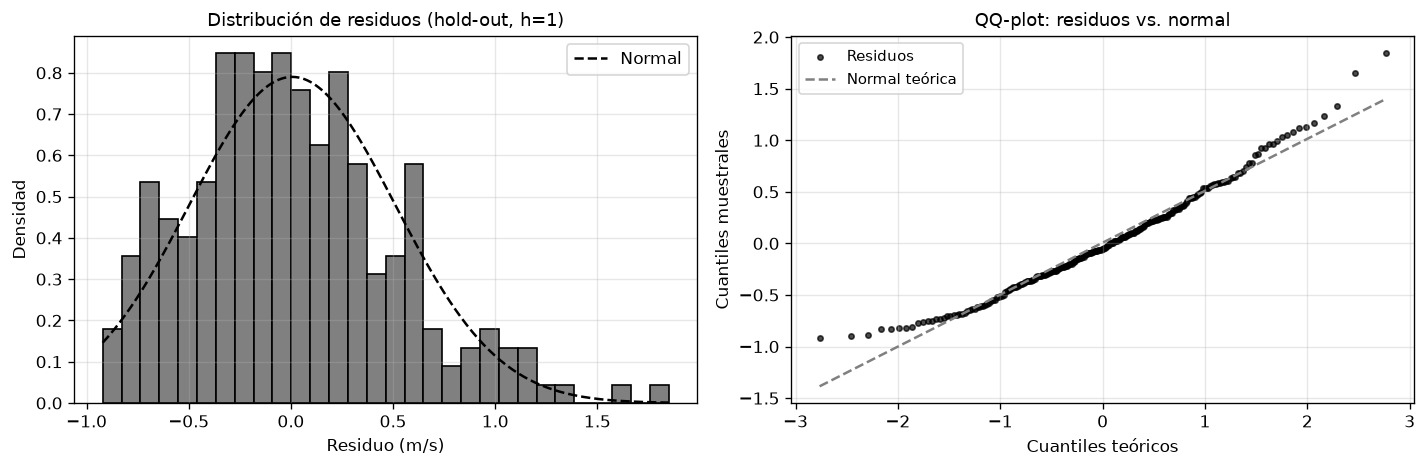

Media residuos  : 0.0067 m/s
Desv. estándar  : 0.5049 m/s
Asimetría       : 0.6028
Curtosis exceso : 0.3833
Prueba de normalidad de D'Agostino-Pearson, p-valor: 0.0005


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(resid_ho, bins=30, edgecolor='black', color='gray', density=True)
xgrid = np.linspace(resid_ho.min(), resid_ho.max(), 200)
axes[0].plot(xgrid, stats.norm.pdf(xgrid, resid_ho.mean(), resid_ho.std()), lw=1.5, ls='--', color='black',
             label='Normal')
axes[0].set_title('Distribución de residuos (hold-out, h=1)')
axes[0].set_xlabel('Residuo (m/s)')
axes[0].set_ylabel('Densidad')
axes[0].legend()

(osm, osr), (pend, inter, _) = stats.probplot(resid_ho, dist='norm')
axes[1].scatter(osm, osr, color='black', s=10, alpha=0.7, label='Residuos')
axes[1].plot(osm, inter + pend * osm, lw=1.5, ls='--', color='gray', label='Normal teórica')
axes[1].set_title('QQ-plot: residuos vs. normal')
axes[1].set_xlabel('Cuantiles teóricos')
axes[1].set_ylabel('Cuantiles muestrales')
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, f'resid_dist_h{H_SHOW}.png'), dpi=150)
plt.show()

_, p_norm = stats.normaltest(resid_ho)
print(f'Media residuos  : {resid_ho.mean():.4f} m/s')
print(f'Desv. estándar  : {resid_ho.std():.4f} m/s')
print(f'Asimetría       : {stats.skew(resid_ho):.4f}')
print(f'Curtosis exceso : {stats.kurtosis(resid_ho):.4f}')
print(f"Prueba de normalidad de D'Agostino-Pearson, p-valor: {p_norm:.4f}")

**Interpretación.** Los residuos del hold-out (H = 7) tienen media de 0,007 m/s y desviación estándar de 0,505 m/s, con asimetría positiva de 0,60 y curtosis en exceso de 0,38. La prueba de D'Agostino-Pearson rechaza la normalidad (p-valor = 0,0005), y en el QQ-plot la desviación se concentra en la cola derecha (D'Agostino & Pearson, 1973).

Así mismo, la asimetría positiva indica que los errores grandes son sobre todo subestimaciones: días de viento fuerte que el modelo predice por debajo, como corresponde a una variable no negativa con cola a la derecha y a un pronóstico que se acerca a la media. La curtosis moderada significa que los eventos extremos son algo más frecuentes que en una normal, pero no dominan el error.

Por esta razón, lo indicado es no construir intervalos de predicción suponiendo normalidad y, si se requieren, estimarlos de forma empírica, por ejemplo con los cuantiles de los residuos de validación.

## 8. Residuos en el tiempo

Residuos de validación de los 5 folds de Forward Chaining y residuos del hold-out del modelo final, para el lag elegido y H = 7, sobre el eje de fechas.

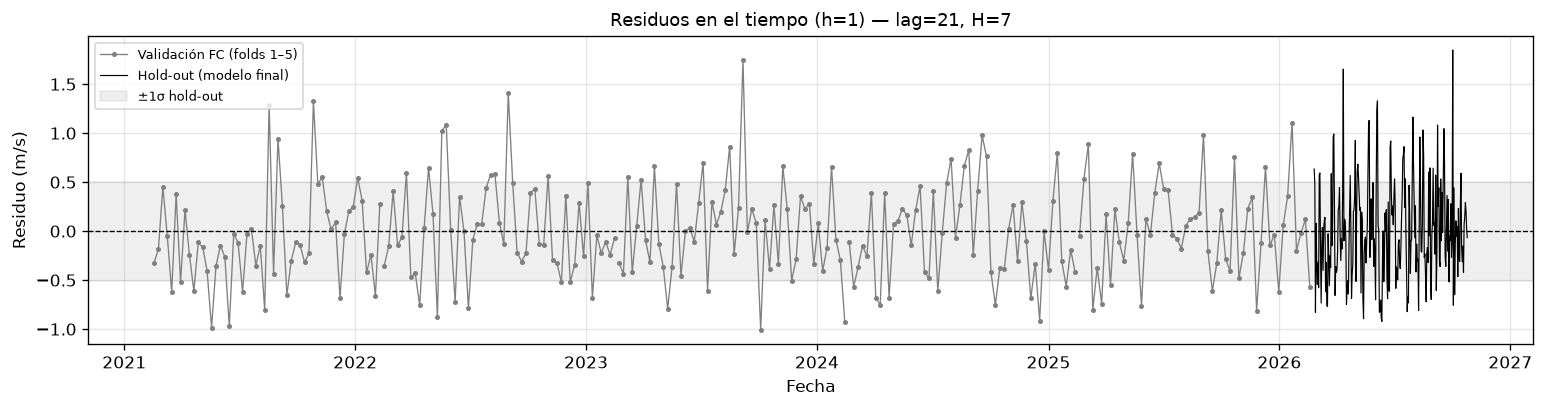

In [7]:
sub = val[(val.estrategia == 'forwardChaining') & (val.lag == LAG_SHOW) & (val.horizonte == H_SHOW)]
ho = ho_pred[ho_pred.horizonte == H_SHOW].sort_values('fecha')
sigma = ho['resid'].std()

fig, ax = plt.subplots(figsize=(13, 3.5))
for fold, g in sub.sort_values('fecha').groupby('fold'):
    ax.plot(g.fecha, g.resid, lw=0.8, marker='o', ms=2, color='gray', label='Validación FC (folds 1–5)' if fold == 1 else None)
ax.plot(ho.fecha, ho.resid, lw=0.7, color='black', label='Hold-out (modelo final)')
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.axhspan(-sigma, sigma, color='gray', alpha=0.12, label='±1σ hold-out')
ax.set_title(f'Residuos en el tiempo (h=1) — lag={LAG_SHOW}, H={H_SHOW}')
ax.set_xlabel('Fecha')
ax.set_ylabel('Residuo (m/s)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, f'resid_tiempo_h{H_SHOW}.png'), dpi=150)
plt.show()

**Interpretación.** En el tiempo, los residuos de validación de Forward Chaining (2021–2026) y los del hold-out oscilan alrededor de cero sin tendencia. En el hold-out el residuo medio por mes cambia de signo: es positivo en mayo (0,12 m/s) y septiembre (0,12 m/s) y negativo en marzo (−0,13 m/s) y junio (−0,07 m/s), y aparecen rachas de varios días del mismo signo, que corresponden a la autocorrelación del rezago 1 de la sección 6.

Esto significa que el modelo no tiene un sesgo sistemático en el periodo, pero sí errores que persisten por tramos: en los meses más ventosos del hold-out, como septiembre, con una media real de 2,33 m/s frente a 1,91 m/s en marzo y abril, se queda corto, y en los más calmados se pasa. Ese patrón apunta a una componente estacional que una ventana de 21 días no alcanza a anticipar.

Por lo anterior, conviene tratar la estacionalidad como la principal línea de mejora y vigilar el sesgo por temporada si el modelo se usa en producción.

## 9. Referencias ingenuas: ¿cuánto aporta el MLP?

Para interpretar las métricas del nivel hace falta compararlas con dos predictores que no aprenden nada:

- **Persistencia:** $\hat y_{t+h} = y_t$, el último valor observado se repite en los $H$ pasos.
- **Media:** $\hat y_{t+h} = \bar y^{\text{train}}_h$, el promedio del objetivo en el entrenamiento del fold.

Se calculan sobre exactamente las mismas ventanas de validación de cada fold (y del hold-out) que el MLP, reconstruidas con la misma función de partición del cuaderno 3. `mejora_%` es la reducción relativa del RMSE del MLP frente a cada referencia; un valor positivo indica que el MLP es mejor.

Con la misma reconstrucción de las ventanas se mide, además, el **solapamiento** entre entrenamiento y validación: el porcentaje de días objetivo de validación que también son días objetivo de alguna ventana de entrenamiento del mismo fold. Es la medida directa de la fuga de información que puede tener cada estrategia.

In [8]:
from tsxv.splitTrainVal import (split_train_val_groupKFold, split_train_val_forwardChaining,
                                split_train_val_kFold)

df_n = pd.read_csv(os.path.join(BASE_DIR, 'data', 'dataset.csv'), parse_dates=['date'])
df_n = df_n[df_n.date >= '2020-01-01'].reset_index(drop=True)
y_n = df_n['wind_speed'].values.astype(np.float32)
n_hold = max(int(len(y_n) * 0.10), 2 * 28)
serie_cv, serie_holdout = y_n[:-n_hold], y_n[-n_hold:]
SPLITS = {'groupKFold': split_train_val_groupKFold, 'forwardChaining': split_train_val_forwardChaining,
          'kFold': split_train_val_kFold}


def particiones(estrategia, n_obs, lag, H, jump=7, k=5):
    """Misma partición del cuaderno 3 (índices temporales, purga en FC y K-Fold)."""
    X, y, Xcv, ycv = SPLITS[estrategia](np.arange(n_obs), numInputs=lag, numOutputs=H, numJumps=jump)
    folds = sorted(X)
    if estrategia == 'groupKFold':
        return [(X[f], y[f], Xcv[f], ycv[f]) for f in folds]
    if estrategia == 'forwardChaining':
        bordes, bloques = np.linspace(0, len(folds), k + 2).astype(int), range(1, k + 1)
    else:
        bordes, bloques = np.linspace(0, len(folds), k + 1).astype(int), range(k)
    salida = []
    for b in bloques:
        fv = folds[bordes[b]:bordes[b + 1]]
        Xv, yv = np.vstack([Xcv[f] for f in fv]), np.vstack([ycv[f] for f in fv])
        Xt, yt = X[fv[0]], y[fv[0]]
        ok = (yt.max(axis=1) < Xv.min()) | (Xt.min(axis=1) > yv.max())
        salida.append((Xt[ok], yt[ok], Xv, yv))
    return salida


def rmse_medio(y_real, y_pred):
    return float(np.mean(np.sqrt(np.mean((y_real - y_pred) ** 2, axis=0))))


fold_df = pd.read_csv(os.path.join(RESULTS_DIR, 'cv_metricas_por_fold.csv'))
filas = []
for (e, lag, H), _ in fold_df.groupby(['estrategia', 'lag', 'horizonte']):
    for fold, (it, iyt, iv, iyv) in enumerate(particiones(e, len(serie_cv), lag, H), 1):
        Xv, yv, yt = serie_cv[iv], serie_cv[iyv], serie_cv[iyt]
        filas.append({'estrategia': e, 'lag': lag, 'horizonte': H, 'fold': fold,
                      'rmse_persistencia': rmse_medio(yv, np.repeat(Xv[:, -1:], H, axis=1)),
                      'rmse_media': rmse_medio(yv, np.broadcast_to(yt.mean(axis=0), yv.shape))})
ingenuas = pd.DataFrame(filas).merge(
    fold_df[['estrategia', 'lag', 'horizonte', 'fold', 'rmse', 'rmse_baseline']],
    on=['estrategia', 'lag', 'horizonte', 'fold'], validate='one_to_one')
ingenuas.to_csv(os.path.join(RESULTS_DIR, 'cv_referencias_ingenuas.csv'), index=False)

res = (ingenuas.groupby(['estrategia', 'horizonte'])
       [['rmse', 'rmse_baseline', 'rmse_persistencia', 'rmse_media']].mean())
res['mejora_vs_persistencia_%'] = (1 - res['rmse'] / res['rmse_persistencia']) * 100
res['mejora_vs_media_%'] = (1 - res['rmse'] / res['rmse_media']) * 100
print('=== Validación: RMSE (m/s) del MLP, MLPRegressor y referencias ingenuas — promedio sobre lags y folds ===')
display(res.round(4))

ho_eval = pd.read_csv(os.path.join(RESULTS_DIR, 'holdout_evaluation.csv'))
filas = []
for r in ho_eval.itertuples():
    lag, H = int(r.lag), int(r.horizonte)
    base = np.concatenate([serie_cv[-lag:], serie_holdout])
    n = len(base) - lag - H + 1
    Xh = np.array([base[i:i + lag] for i in range(n)])
    yh = np.array([base[i + lag:i + lag + H] for i in range(n)])
    X, y, Xcv, ycv = split_train_val_forwardChaining(np.arange(len(serie_cv)), numInputs=lag, numOutputs=H, numJumps=7)
    u = max(X)
    media_train = serie_cv[np.vstack([y[u], ycv[u]])].mean(axis=0)
    p, m = rmse_medio(yh, np.repeat(Xh[:, -1:], H, axis=1)), rmse_medio(yh, np.broadcast_to(media_train, yh.shape))
    filas.append({'horizonte': H, 'lag': lag, 'rmse_mlp': r.holdout_rmse, 'rmse_persistencia': p, 'rmse_media': m,
                  'mejora_vs_persistencia_%': (1 - r.holdout_rmse / p) * 100,
                  'mejora_vs_media_%': (1 - r.holdout_rmse / m) * 100})
ho_ing = pd.DataFrame(filas)
ho_ing.to_csv(os.path.join(RESULTS_DIR, 'holdout_referencias_ingenuas.csv'), index=False)
print('=== Hold-out: RMSE (m/s) del modelo final frente a las referencias ingenuas ===')
display(ho_ing.round(4))

solape = []
for e in SPLITS:
    for lag in [7, 14, 21, 28]:
        for H in [7, 14, 21, 28]:
            for fold, (it, iyt, iv, iyv) in enumerate(particiones(e, len(serie_cv), lag, H), 1):
                solape.append({'estrategia': e, 'horizonte': H,
                               'solape_%': float(np.isin(np.unique(iyv), np.unique(iyt)).mean() * 100)})
solape = pd.DataFrame(solape)
print('=== Validación: días objetivo de validación que también son objetivo en entrenamiento (%) — promedio por estrategia y H ===')
display(solape.pivot_table(index='estrategia', columns='horizonte', values='solape_%', aggfunc='mean').round(1)
        .assign(promedio=solape.groupby('estrategia')['solape_%'].mean().round(1)))

=== Validación: RMSE (m/s) del MLP, MLPRegressor y referencias ingenuas — promedio sobre lags y folds ===


rmse  rmse_baseline  rmse_persistencia  \
estrategia      horizonte                                             
forwardChaining 7          0.5534         0.6832             0.7193   
                14         0.5619         0.6774             0.7434   
                21         0.5644         0.6713             0.7585   
                28         0.5659         0.6637             0.7591   
groupKFold      7          0.5560         0.7014             0.7186   
                14         0.5700         0.6890             0.7532   
                21         0.5704         0.6841             0.7707   
                28         0.5706         0.6760             0.7698   
kFold           7          0.5613         0.6839             0.7165   
                14         0.5699         0.6612             0.7482   
                21         0.5715         0.6525             0.7661   
                28         0.5725         0.6454             0.7683   

                           rmse_media  mejora_vs_persistencia_%  \
estrategia      horizonte                                         
forwardChaining 7              0.5681                   23.0631   
                14             0.5683                   24.4167   
                21             0.5689                   25.5963   
                28             0.5693                   25.4514   
groupKFold      7              0.5677                   22.6253   
                14             0.5727                   24.3206   
                21             0.5733                   25.9883   
                28             0.5729                   25.8700   
kFold           7              0.5783                   21.6562   
                14             0.5775                   23.8397   
                21             0.5776                   25.4062   
                28             0.5774                   25.4904   

                           mejora_vs_media_%  
estrategia      horizonte                     
forwardChaining 7                     2.5897  
                14                    1.1371  
                21                    0.7953  
                28                    0.6093  
groupKFold      7                     2.0631  
                14                    0.4646  
                21                    0.5131  
                28                    0.4042  
kFold           7                     2.9308  
                14                    1.3238  
                21                    1.0488  
                28                    0.8630

=== Hold-out: RMSE (m/s) del modelo final frente a las referencias ingenuas ===


,horizonte,lag,rmse_mlp,rmse_persistencia,rmse_media,mejora_vs_persistencia_%,mejora_vs_media_%
0,7,21,0.5750,0.7638,0.5637,24.7118,-2.0100
1,14,21,0.5674,0.7994,0.5660,29.0269,-0.2382
2,21,21,0.5732,0.8036,0.5692,28.6636,-0.7150
3,28,21,0.5728,0.8138,0.5718,29.6086,-0.1888


=== Validación: días objetivo de validación que también son objetivo en entrenamiento (%) — promedio por estrategia y H ===


horizonte,7,14,21,28,promedio
estrategia,,,,,
forwardChaining,0.0,0.0,0.0,0.0,0.0
groupKFold,0.0,24.9,41.5,62.2,32.1
kFold,0.0,0.0,0.0,0.0,0.0


**Interpretación.** En validación, el MLP reduce el RMSE de la persistencia entre un 23 % y un 26 % en Forward Chaining (de 0,719–0,759 m/s a 0,553–0,566 m/s), pero frente a la media del entrenamiento la mejora es pequeña y decrece con el horizonte: 2,6 % con H = 7, 1,1 % con H = 14, 0,8 % con H = 21 y 0,6 % con H = 28. En el hold-out la ventaja sobre la persistencia se mantiene (25 % a 30 %), pero frente a la media el RMSE del MLP queda entre un 0,2 % y un 2,0 % por encima. El solapamiento confirma la prueba de fugas: en Forward Chaining y K-Fold ningún día objetivo de validación está en el entrenamiento, mientras en Group K-Fold lo está el 32,1 % en promedio, con un valor que crece con el horizonte, de 0 % con H = 7 a 62,2 % con H = 28.

Esto significa que el MLP aprende el nivel medio del viento y una fracción pequeña de su dinámica de corto plazo, que se diluye con el horizonte y no se sostiene en el hold-out. La persistencia es una referencia débil para esta serie, porque repetir el valor de un solo día con tanta variabilidad diaria amplifica el error, y por eso superarla no basta para afirmar que el modelo aporta (Hyndman & Athanasopoulos, 2021). Igual, el solapamiento de Group K-Fold muestra que su fuga existe y es grande en horizontes largos, aunque, como el modelo predice cerca de la media, no se traduzca en un RMSE menor (cuaderno 3, sección 7).

Por tal motivo, se opta por reportar con transparencia que, solo con el pasado de la propia serie, el MLP no supera de forma consistente a la media climatológica, y por dejar como trabajo futuro las extensiones que el enunciado permite, la estacionalidad derivada de la fecha y una regularización menos agresiva, en lugar de forzar el modelo actual.

## 10. Conclusiones

1. En validación, los residuos del primer paso son compatibles con independencia en la mayoría de los folds (95 % en Forward Chaining), pero a escala semanal y con poca potencia por el tamaño de los folds.
2. En el hold-out, con residuos diarios consecutivos, la prueba BDS rechaza la independencia en los cuatro horizontes. La ACF ubica esa dependencia en el rezago 1 (0,334), es decir, memoria de muy corto plazo, y la heterocedasticidad residual es débil (0,139 en los cuadrados).
3. Los residuos no tienen sesgo (media de 0,007 m/s), pero no son normales: la asimetría positiva de 0,60 refleja la subestimación de los días de viento fuerte, de modo que los intervalos de predicción deben estimarse de forma empírica.
4. Frente a las referencias ingenuas, el MLP supera ampliamente a la persistencia (cerca de un 25 %), pero no a la media en el hold-out: la velocidad media diaria del viento tiene poca predictibilidad a partir de su propio pasado en horizontes de 7 a 28 días.
5. Group K-Fold comparte en promedio el 32,1 % de los días objetivo entre entrenamiento y validación, y hasta el 62,2 % con H = 28, lo que confirma su riesgo de fuga, mientras Forward Chaining y K-Fold, con purga, no comparten ninguno.
6. La estacionalidad visible en los residuos por mes y la memoria de corto plazo sin capturar orientan las mejoras: variables derivadas de la fecha, menos dropout y, para el corto plazo, una corrección autorregresiva de los residuos.

## Referencias

- Brock, W. A., Dechert, W. D., Scheinkman, J. A., & LeBaron, B. (1996). A test for independence based on the correlation dimension. *Econometric Reviews*, 15(3), 197–235.
- D'Agostino, R., & Pearson, E. S. (1973). Tests for departure from normality. *Biometrika*, 60(3), 613–622.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3.ª ed.). OTexts.